<a href="https://colab.research.google.com/github/NatShed/MLAttacl_FINAL_PROJECT/blob/main/Final_project_CovidXray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Работа выполнена студентами Любов Кирилл и Щедрина Наталья, группа БАС-2021  
Выбранный датасет для финального проекта - https://www.kaggle.com/datasets/ahemateja19bec1025/covid-xray-dataset?resource=download

# Подготовка окружения


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
import torchvision.transforms.functional as TF
from torchvision.datasets import ImageFolder

import torchattacks
from torchmetrics import Accuracy, Precision, Recall, F1Score
from torchmetrics.classification import MulticlassConfusionMatrix

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(333)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")
print(f"PyTorch версия: {torch.__version__}")

Устройство: cuda
PyTorch версия: 2.14.1+cu130


In [ ]:
# ============================================================
# Ячейка 0. Установка недостающих пакетов
# ============================================================
!pip install -q torchattacks torchmetrics

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.25.1 which is incompatible.
tweepy 4.17.0 requires requests<3,>=2.27.0, but you have requests 2.25.1 which is incompatible.
datasets 4.8.5 requires requests>=2.32.2, but you have requests 2.25.1 which is incompatible.
bigframes 2.51.0 requires requests>=2.27.1, but you have requests 2.25.1 which is incompatible.
httpx2 2.16.0 requires idna>=3.18, but you have idna 2.10 which is incompatible.
blobfile 3.3.0 requires urllib3>=2, but you have urllib3 1.26.20 which is incompatible.
libpysal 4.14.1 requires requests>=2.32.0, but you have requests 2.25.1 which is incompatible.
sphinx 8.2.3 requires requests>=2.30.0, but you have requests 2.25.1 which is incompatible.
yfinance 0.2.66 requires requests>=2.31, but you have requests 2.25.1 which is incomp

# Загрузка датасета Covid Xray

In [ ]:
from google.colab import files

print("Загрузите файл kaggle.json (https://www.kaggle.com/account):")
uploaded = files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# --force, чтобы гарантированно перекачать архив
!kaggle datasets download -d ahemateja19bec1025/covid-xray-dataset --force

# -o, чтобы не спрашивать про замену файлов при повторном запуске
!unzip -o -q covid-xray-dataset.zip -d /content/covid_xray

print("\nСодержимое директории:")
!find /content/covid_xray -maxdepth 3 -type d | head -30

Загрузите файл kaggle.json (https://www.kaggle.com/account):


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ahemateja19bec1025/covid-xray-dataset
License(s): CC0-1.0
100% 1.04G/1.04G [01:01<00:00, 18.1MB/s]


Содержимое директории:
/content/covid_xray
/content/covid_xray/DATA
/content/covid_xray/DATA/DATA
/content/covid_xray/DATA/DATA/0
/content/covid_xray/DATA/DATA/1


# Подготовка данных к обучению

In [ ]:
from collections import Counter

DATA_ROOT = "/content/covid_xray/DATA/DATA"
assert os.path.isdir(DATA_ROOT), f"Путь не найден: {DATA_ROOT}"

IMG_SIZE = 224
BATCH_SIZE = 32

baseline_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = ImageFolder(root=DATA_ROOT, transform=baseline_transform)
class_names = full_dataset.classes
num_classes = len(class_names)
print(f"Всего изображений: {len(full_dataset)}")
print(f"Классы: {class_names}  (0 = нет ковида, 1 = есть ковид)")

labels_all = [label for _, label in full_dataset.samples]
label_counts = Counter(labels_all)
print("\nРаспределение по классам:")
for cls_idx in sorted(label_counts.keys()):
    count = label_counts[cls_idx]
    pct = 100 * count / len(full_dataset)
    print(f"  Класс {cls_idx} ('{class_names[cls_idx]}'): {count} ({pct:.1f}%)")

total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("\nРазбиение выборки:")
print(f"  Train: {len(train_dataset)}")
print(f"  Val:   {len(val_dataset)}")
print(f"  Test:  {len(test_dataset)}")


def split_class_counts(subset, name):
    subset_labels = [full_dataset.samples[i][1] for i in subset.indices]
    cnt = Counter(subset_labels)
    print(f"  {name}: " + ", ".join(
        f"class {c} = {cnt.get(c, 0)}" for c in range(num_classes)))


print("\nБаланс классов:")
split_class_counts(train_dataset, "Train")
split_class_counts(val_dataset, "Val")
split_class_counts(test_dataset, "Test")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"\nБатчей: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")

images, labels_batch = next(iter(train_loader))
print(f"\nФорма батча: {images.shape}, пример меток: {labels_batch[:8].tolist()}")

Всего изображений: 3091
Классы: ['0', '1']  (0 = нет ковида, 1 = есть ковид)

Распределение по классам:
  Класс 0 ('0'): 1301 (42.1%)
  Класс 1 ('1'): 1790 (57.9%)

Разбиение выборки:
  Train: 2163
  Val:   463
  Test:  465

Баланс классов:
  Train: class 0 = 909, class 1 = 1254
  Val: class 0 = 209, class 1 = 254
  Test: class 0 = 183, class 1 = 282

Батчей: train=68, val=15, test=15

Форма батча: torch.Size([32, 3, 224, 224]), пример меток: [1, 1, 1, 1, 1, 0, 0, 1]


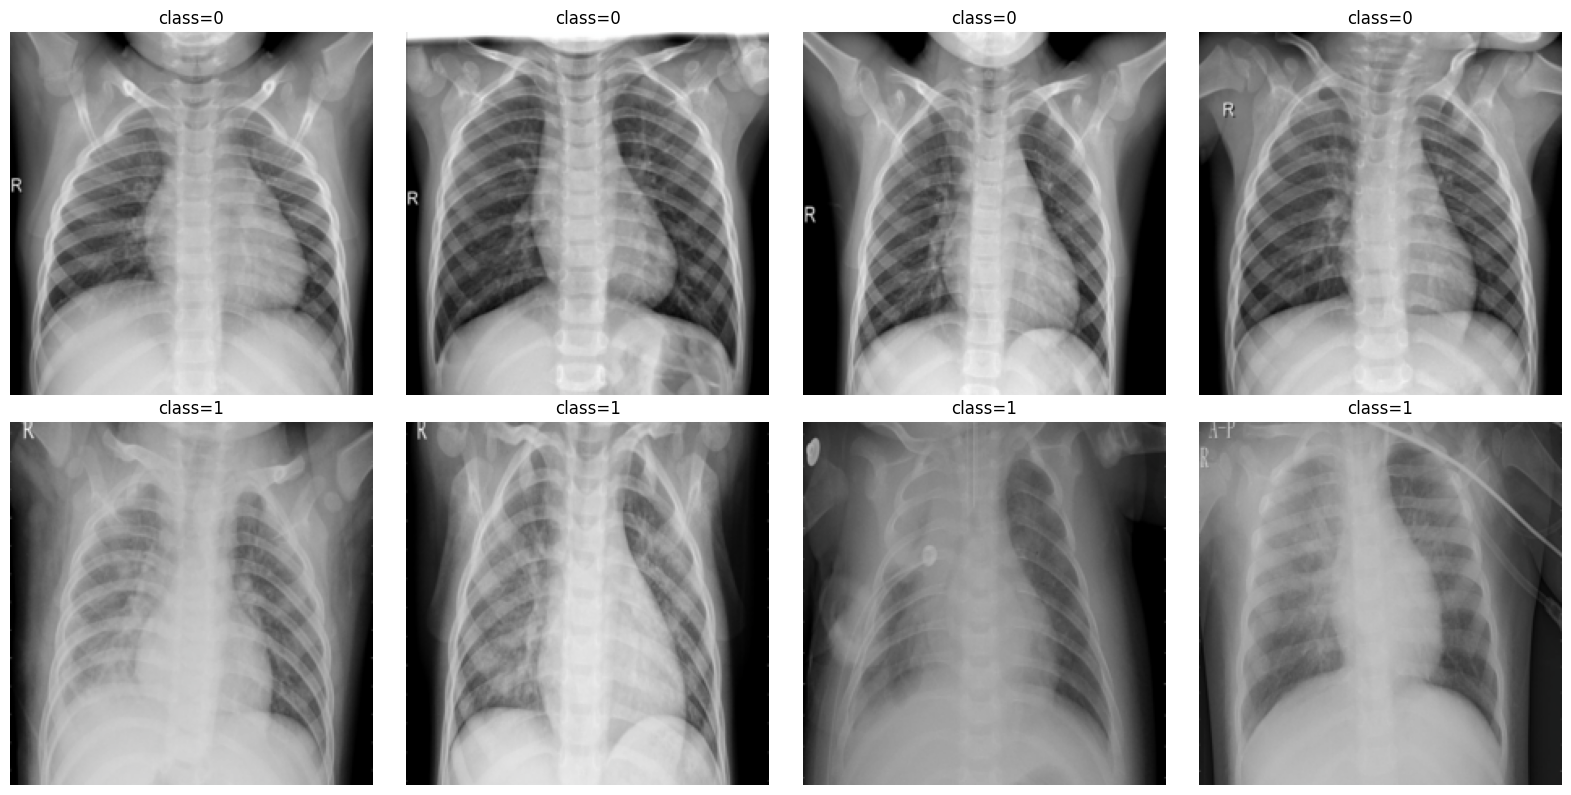

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

class_indices = {i: [] for i in range(num_classes)}
for idx, (_, label) in enumerate(full_dataset.samples):
    class_indices[label].append(idx)

plot_idx = 0
for cls_id in range(num_classes):
    for _ in range(min(4, len(class_indices[cls_id]))):
        idx = random.choice(class_indices[cls_id])
        img, label = full_dataset[idx]
        img_show = img.permute(1, 2, 0).numpy()
        img_show = np.clip(img_show * np.array([0.229, 0.224, 0.225])
                           + np.array([0.485, 0.456, 0.406]), 0, 1)
        axes[plot_idx].imshow(img_show)
        axes[plot_idx].set_title(f"class={class_names[label]}")
        axes[plot_idx].axis('off')
        plot_idx += 1
        if plot_idx >= 8:
            break
    if plot_idx >= 8:
        break

plt.tight_layout()
plt.show()

# Baseline модель

In [ ]:
def create_baseline_model(num_classes, device):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

baseline_model = create_baseline_model(num_classes, device)

total_params = sum(p.numel() for p in baseline_model.parameters())
trainable_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print(f"Всего параметров: {total_params:,}")
print(f"Обучаемых параметров: {trainable_params:,}")

criterion = nn.CrossEntropyLoss()
optimizer_baseline = optim.Adam(baseline_model.parameters(), lr=0.001)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


Всего параметров: 11,177,538
Обучаемых параметров: 11,177,538


In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    return running_loss / total, correct / total


def evaluate(model, loader, criterion, device, return_predictions=False):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    preds_t = torch.tensor(all_preds)
    labels_t = torch.tensor(all_labels)

    precision = Precision(task="multiclass", num_classes=num_classes, average='macro')
    recall = Recall(task="multiclass", num_classes=num_classes, average='macro')
    f1 = F1Score(task="multiclass", num_classes=num_classes, average='macro')
    precision.update(preds_t, labels_t)
    recall.update(preds_t, labels_t)
    f1.update(preds_t, labels_t)

    result = {
        'loss': running_loss / total,
        'accuracy': correct / total,
        'precision': precision.compute().item(),
        'recall': recall.compute().item(),
        'f1': f1.compute().item(),
    }
    if return_predictions:
        result['preds'] = np.array(all_preds)
        result['labels'] = np.array(all_labels)
    return result


def evaluate_under_attack(model, attack, loader, device, return_predictions=False):
    """Атака untargeted: передаём истинные метки."""
    model.eval()
    correct = 0
    total = 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        adv_images = attack(images, labels)
        with torch.no_grad():
            outputs = model(adv_images)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    result = {'accuracy': correct / total}
    if return_predictions:
        result['preds'] = np.array(all_preds)
        result['labels'] = np.array(all_labels)
    return result


def plot_confusion_matrix(preds, labels, title, class_names):
    cm = MulticlassConfusionMatrix(num_classes=num_classes)
    cm_tensor = cm(torch.tensor(preds), torch.tensor(labels)).numpy()
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_tensor, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return cm_tensor

In [ ]:
EPOCHS_BASELINE = 10
best_val_acc = 0.0
baseline_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("=" * 60)
print("ОБУЧЕНИЕ BASELINE (10 эпох, все параметры обучаемы)")
print("=" * 60)

for epoch in range(EPOCHS_BASELINE):
    train_loss, train_acc = train_epoch(
        baseline_model, train_loader, criterion, optimizer_baseline, device)
    val_metrics = evaluate(baseline_model, val_loader, criterion, device)

    baseline_history['train_loss'].append(train_loss)
    baseline_history['train_acc'].append(train_acc)
    baseline_history['val_loss'].append(val_metrics['loss'])
    baseline_history['val_acc'].append(val_metrics['accuracy'])

    print(f"Epoch {epoch+1}/{EPOCHS_BASELINE}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val P: {val_metrics['precision']:.4f} | R: {val_metrics['recall']:.4f} | F1: {val_metrics['f1']:.4f}")

    if val_metrics['accuracy'] > best_val_acc:
        best_val_acc = val_metrics['accuracy']
        torch.save(baseline_model.state_dict(), 'baseline_best.pth')
        print(f"  → Сохранена лучшая модель (val_acc={best_val_acc:.4f})")
    print()

baseline_model.load_state_dict(torch.load('baseline_best.pth'))
print(f"Лучшая Baseline Val Accuracy: {best_val_acc:.4f}")

ОБУЧЕНИЕ BASELINE (10 эпох, все параметры обучаемы)
Epoch 1/10
  Train Loss: 0.1572 | Train Acc: 0.9417
  Val Loss: 0.0967 | Val Acc: 0.9611
  Val P: 0.9599 | R: 0.9624 | F1: 0.9609
  → Сохранена лучшая модель (val_acc=0.9611)

Epoch 2/10
  Train Loss: 0.0474 | Train Acc: 0.9815
  Val Loss: 0.0659 | Val Acc: 0.9741
  Val P: 0.9738 | R: 0.9738 | F1: 0.9738
  → Сохранена лучшая модель (val_acc=0.9741)

Epoch 3/10
  Train Loss: 0.0704 | Train Acc: 0.9755
  Val Loss: 0.2028 | Val Acc: 0.9546
  Val P: 0.9540 | R: 0.9582 | F1: 0.9545

Epoch 4/10
  Train Loss: 0.0549 | Train Acc: 0.9797
  Val Loss: 0.2517 | Val Acc: 0.9158
  Val P: 0.9334 | R: 0.9067 | F1: 0.9129

Epoch 5/10
  Train Loss: 0.0390 | Train Acc: 0.9861
  Val Loss: 0.0872 | Val Acc: 0.9719
  Val P: 0.9708 | R: 0.9731 | F1: 0.9717

Epoch 6/10
  Train Loss: 0.0164 | Train Acc: 0.9935
  Val Loss: 0.0815 | Val Acc: 0.9784
  Val P: 0.9782 | R: 0.9782 | F1: 0.9782
  → Сохранена лучшая модель (val_acc=0.9784)

Epoch 7/10
  Train Loss: 0.

# Оценка baseline модели на тестовой выборке

BASELINE — ЧИСТЫЕ ДАННЫЕ
Accuracy:  0.9785
Precision: 0.9775
Recall:    0.9775
F1-Score:  0.9775
Loss:      0.0509


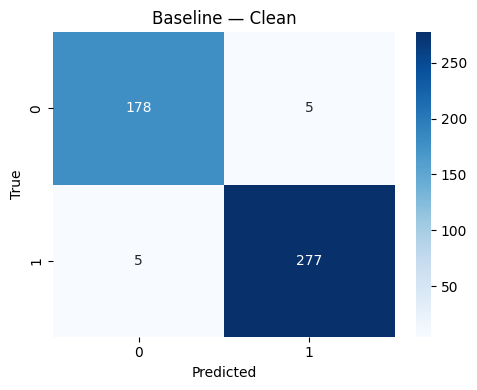


Baseline — FGSM Accuracy: 0.6065


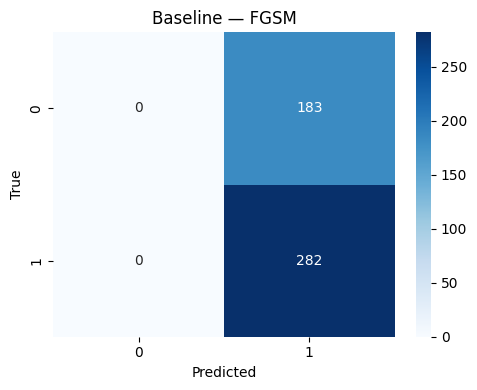

Baseline — PGD Accuracy: 0.2882


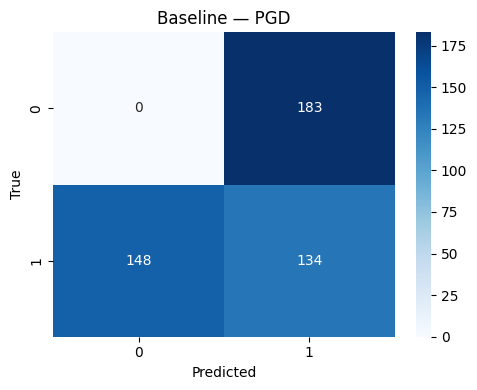

array([[  0, 183],
       [148, 134]])

In [ ]:
test_metrics_baseline = evaluate(
    baseline_model, test_loader, criterion, device, return_predictions=True)

print("=" * 60)
print("BASELINE — ЧИСТЫЕ ДАННЫЕ")
print("=" * 60)
print(f"Accuracy:  {test_metrics_baseline['accuracy']:.4f}")
print(f"Precision: {test_metrics_baseline['precision']:.4f}")
print(f"Recall:    {test_metrics_baseline['recall']:.4f}")
print(f"F1-Score:  {test_metrics_baseline['f1']:.4f}")
print(f"Loss:      {test_metrics_baseline['loss']:.4f}")

plot_confusion_matrix(test_metrics_baseline['preds'], test_metrics_baseline['labels'],
                      'Baseline — Clean', class_names)

# FGSM
fgsm_baseline = torchattacks.FGSM(baseline_model, eps=8/255)
baseline_fgsm = evaluate_under_attack(
    baseline_model, fgsm_baseline, test_loader, device, return_predictions=True)
baseline_fgsm_acc = baseline_fgsm['accuracy']
print(f"\nBaseline — FGSM Accuracy: {baseline_fgsm_acc:.4f}")
plot_confusion_matrix(baseline_fgsm['preds'], baseline_fgsm['labels'],
                      'Baseline — FGSM', class_names)

# PGD
pgd_baseline = torchattacks.PGD(baseline_model, eps=8/255, alpha=2/255, steps=10)
baseline_pgd = evaluate_under_attack(
    baseline_model, pgd_baseline, test_loader, device, return_predictions=True)
baseline_pgd_acc = baseline_pgd['accuracy']
print(f"Baseline — PGD Accuracy: {baseline_pgd_acc:.4f}")
plot_confusion_matrix(baseline_pgd['preds'], baseline_pgd['labels'],
                      'Baseline — PGD', class_names)

# Подготовка и обучение защищенной модели

In [ ]:
class RobustAugDataset(Dataset):
    def __init__(self, base_dataset, img_size=224,
                 rotate_angles=(-30, -15, 0, 15, 30),
                 noise_stds=(0.0, 0.0, 0.05, 0.1),
                 p_rotate=0.5, p_noise=0.5):
        self.base_dataset = base_dataset
        self.img_size = img_size
        self.rotate_angles = rotate_angles
        self.noise_stds = noise_stds
        self.p_rotate = p_rotate
        self.p_noise = p_noise
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        real_idx = self.base_dataset.indices[idx]
        img_path, label = self.base_dataset.dataset.samples[real_idx]
        img = Image.open(img_path).convert("RGB")
        img = img.resize((self.img_size, self.img_size))
        if random.random() < self.p_rotate:
            angle = random.choice(self.rotate_angles)
            img = TF.rotate(img, angle)
        img_t = TF.to_tensor(img)
        if random.random() < self.p_noise:
            std = random.choice(self.noise_stds)
            if std > 0:
                img_t = torch.clamp(img_t + torch.randn_like(img_t) * std, 0.0, 1.0)
        img_t = (img_t - self.mean) / self.std
        return img_t, label


robust_aug_train = RobustAugDataset(
    train_dataset, img_size=IMG_SIZE,
    rotate_angles=(-30, -15, 0, 15, 30),
    noise_stds=(0.0, 0.05, 0.1, 0.15),
    p_rotate=0.5, p_noise=0.5,
)
robust_aug_loader = DataLoader(robust_aug_train, batch_size=BATCH_SIZE,
                                shuffle=True, num_workers=2)

print(f"Датасет для дообучения: {len(robust_aug_train)} примеров, "
      f"{len(robust_aug_loader)} батчей")
print(f"Аугментации: повороты {robust_aug_train.rotate_angles}, "
      f"шум std {robust_aug_train.noise_stds}")

Датасет для дообучения: 2163 примеров, 68 батчей
Аугментации: повороты (-30, -15, 0, 15, 30), шум std (0.0, 0.05, 0.1, 0.15)


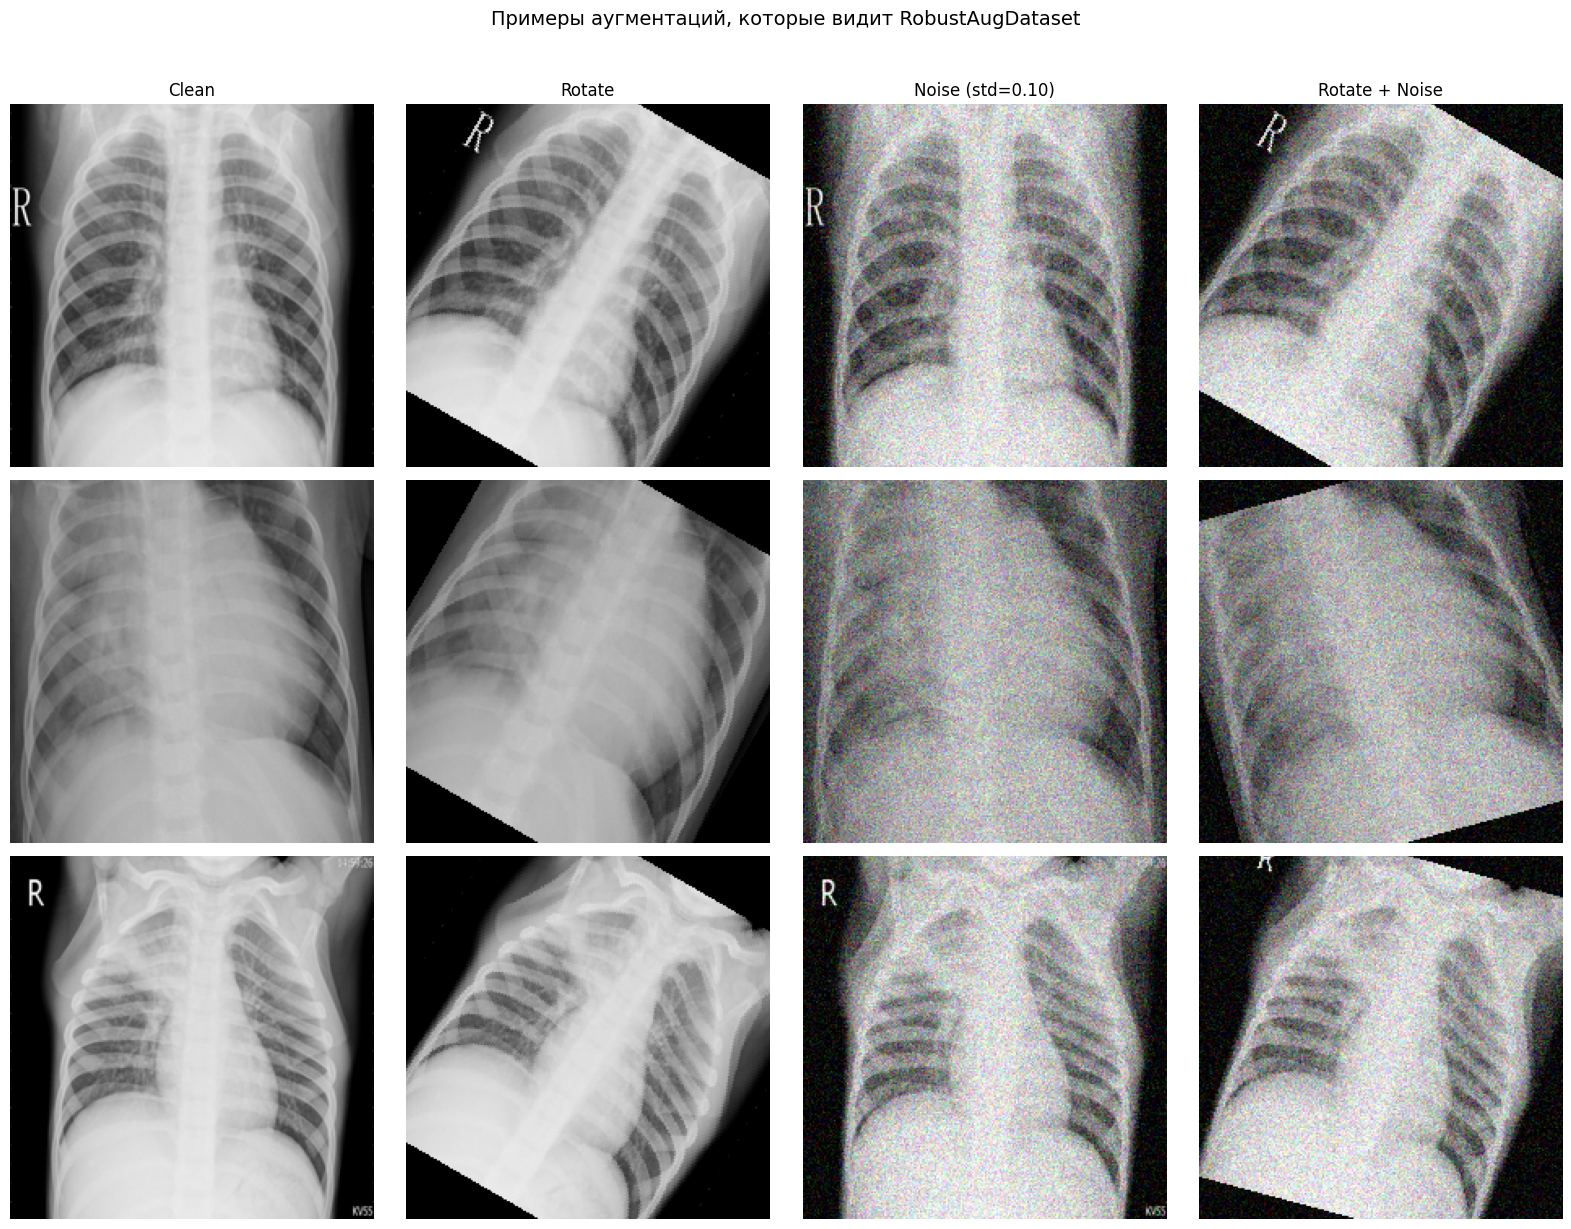

In [ ]:
# Денормализация для отображения
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def denorm(img_t):
    """[C,H,W] нормализованный тензор -> numpy [H,W,C] в [0,1]."""
    x = img_t.cpu() * _STD + _MEAN
    return np.clip(x.permute(1, 2, 0).numpy(), 0, 1)


def load_raw(idx):
    """Достаём исходное изображение из underlying ImageFolder (без трансформаций)."""
    real_idx = train_dataset.indices[idx]
    img_path, label = train_dataset.dataset.samples[real_idx]
    img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    return img, label


# Фиксируем seed, чтобы картинка была воспроизводимой
random.seed(7)

# 3 случайных примера из train
sample_idx = random.sample(range(len(train_dataset)), 3)

scenarios = ["Clean", "Rotate", "Noise (std=0.10)", "Rotate + Noise"]

fig, axes = plt.subplots(len(sample_idx), len(scenarios),
                          figsize=(4 * len(scenarios), 4 * len(sample_idx)))
if len(sample_idx) == 1:
    axes = axes.reshape(1, -1)

for row, idx in enumerate(sample_idx):
    img_raw, label = load_raw(idx)
    cls_name = class_names[label]

    for col, scenario in enumerate(scenarios):
        img = img_raw.copy()

        if scenario in ("Rotate", "Rotate + Noise"):
            # случайный ненулевой угол
            angle = random.choice([a for a in (-30, -15, 15, 30)])
            img = TF.rotate(img, angle)

        img_t = TF.to_tensor(img)  # [C,H,W], значения в [0,1]

        if scenario in ("Noise (std=0.10)", "Rotate + Noise"):
            std = 0.10
            noise = torch.randn_like(img_t) * std
            img_t = torch.clamp(img_t + noise, 0.0, 1.0)

        img_t = (img_t - _MEAN) / _STD
        img_show = denorm(img_t)

        axes[row, col].imshow(img_show)
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(scenario, fontsize=12)
        if col == 0:
            axes[row, col].set_ylabel(f"class={cls_name}", fontsize=12)

plt.suptitle("Примеры аугментаций, которые видит RobustAugDataset",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
def create_robust_model(num_classes, device):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)


robust_model = create_robust_model(num_classes, device)
optimizer_robust = optim.Adam(robust_model.parameters(), lr=0.001)

ADV_EPS = 8 / 255
ADV_ALPHA = 2 / 255
ADV_STEPS = 7

print("Защищённая модель создана")
print(f"Adversarial training: eps={ADV_EPS:.4f}, alpha={ADV_ALPHA:.4f}, steps={ADV_STEPS}")

Защищённая модель создана
Adversarial training: eps=0.0314, alpha=0.0078, steps=7


In [ ]:
def adversarial_train_epoch(model, loader, criterion, optimizer, device,
                            pgd_attack, fgsm_attack):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # Генерируем adv-примеры в eval-режиме (атака не должна видеть BN-статистики обучения)
        model.eval()
        adv_pgd = pgd_attack(images, labels)
        adv_fgsm = fgsm_attack(images, labels)
        model.train()

        optimizer.zero_grad()

        outputs_clean = model(images)
        loss_clean = criterion(outputs_clean, labels)

        outputs_pgd = model(adv_pgd)
        loss_pgd = criterion(outputs_pgd, labels)

        outputs_fgsm = model(adv_fgsm)
        loss_fgsm = criterion(outputs_fgsm, labels)

        loss = (loss_clean + loss_pgd + loss_fgsm) / 3.0
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs_clean.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, correct / total


EPOCHS_ROBUST = 5
best_robust_val_acc = 0.0
robust_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

pgd_train = torchattacks.PGD(robust_model, eps=ADV_EPS, alpha=ADV_ALPHA, steps=ADV_STEPS)
fgsm_train = torchattacks.FGSM(robust_model, eps=ADV_EPS)

print("=" * 60)
print("ОБУЧЕНИЕ ЗАЩИЩЁННОЙ МОДЕЛИ (PGD + FGSM)")
print("=" * 60)

for epoch in range(EPOCHS_ROBUST):
    train_loss, train_acc = adversarial_train_epoch(
        robust_model, train_loader, criterion, optimizer_robust, device,
        pgd_train, fgsm_train,
    )
    val_metrics = evaluate(robust_model, val_loader, criterion, device)

    robust_history['train_loss'].append(train_loss)
    robust_history['train_acc'].append(train_acc)
    robust_history['val_loss'].append(val_metrics['loss'])
    robust_history['val_acc'].append(val_metrics['accuracy'])

    print(f"Epoch {epoch+1}/{EPOCHS_ROBUST}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val P: {val_metrics['precision']:.4f} | R: {val_metrics['recall']:.4f} | F1: {val_metrics['f1']:.4f}")

    if val_metrics['accuracy'] > best_robust_val_acc:
        best_robust_val_acc = val_metrics['accuracy']
        torch.save(robust_model.state_dict(), 'robust_best.pth')
        print(f"  → Сохранена лучшая защищённая модель (val_acc={best_robust_val_acc:.4f})")
    print()

robust_model.load_state_dict(torch.load('robust_best.pth'))
print(f"Лучшая Robust Val Accuracy: {best_robust_val_acc:.4f}")

ОБУЧЕНИЕ ЗАЩИЩЁННОЙ МОДЕЛИ (PGD + FGSM)
Epoch 1/5
  Train Loss: 0.2976 | Train Acc: 0.9330
  Val Loss: 0.4405 | Val Acc: 0.8294
  Val P: 0.8784 | R: 0.8114 | F1: 0.8166
  → Сохранена лучшая защищённая модель (val_acc=0.8294)

Epoch 2/5
  Train Loss: 0.1406 | Train Acc: 0.9621
  Val Loss: 0.1560 | Val Acc: 0.9482
  Val P: 0.9470 | R: 0.9506 | F1: 0.9479
  → Сохранена лучшая защищённая модель (val_acc=0.9482)

Epoch 3/5
  Train Loss: 0.1018 | Train Acc: 0.9760
  Val Loss: 0.0657 | Val Acc: 0.9719
  Val P: 0.9719 | R: 0.9714 | F1: 0.9716
  → Сохранена лучшая защищённая модель (val_acc=0.9719)

Epoch 4/5
  Train Loss: 0.0732 | Train Acc: 0.9820
  Val Loss: 0.0786 | Val Acc: 0.9698
  Val P: 0.9685 | R: 0.9716 | F1: 0.9696

Epoch 5/5
  Train Loss: 0.0629 | Train Acc: 0.9884
  Val Loss: 0.1217 | Val Acc: 0.9611
  Val P: 0.9601 | R: 0.9641 | F1: 0.9610

Лучшая Robust Val Accuracy: 0.9719


In [ ]:
def robust_finetune_epoch(model, clean_loader, aug_loader, criterion, optimizer,
                          device, pgd_attack, fgsm_attack):
    """
    Комбинированное дообучение:
      - 0.4 * clean  (реальные чистые батчи из clean_loader)
      - 0.3 * aug    (поворот + шум из aug_loader)
      - 0.15 * PGD
      - 0.15 * FGSM
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # Оба лоадера строятся по одному и тому же train_dataset => одинаковая длина
    for (clean_images, clean_labels), (aug_images, aug_labels) in zip(clean_loader, aug_loader):
        clean_images = clean_images.to(device)
        clean_labels = clean_labels.to(device)
        aug_images = aug_images.to(device)
        aug_labels = aug_labels.to(device)

        # 1) clean loss
        outputs_clean = model(clean_images)
        loss_clean = criterion(outputs_clean, clean_labels)

        # 2) aug loss
        outputs_aug = model(aug_images)
        loss_aug = criterion(outputs_aug, aug_labels)

        # 3) adversarial — на чистых, чтобы атака не билась об уже испорченные данные
        model.eval()
        adv_pgd = pgd_attack(clean_images, clean_labels)
        adv_fgsm = fgsm_attack(clean_images, clean_labels)
        model.train()

        outputs_pgd = model(adv_pgd)
        loss_pgd = criterion(outputs_pgd, clean_labels)

        outputs_fgsm = model(adv_fgsm)
        loss_fgsm = criterion(outputs_fgsm, clean_labels)

        loss = 0.4 * loss_clean + 0.3 * loss_aug + 0.15 * loss_pgd + 0.15 * loss_fgsm

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * clean_images.size(0)
        _, predicted = outputs_clean.max(1)
        total += clean_labels.size(0)
        correct += predicted.eq(clean_labels).sum().item()

    return running_loss / total, correct / total


FINETUNE_EPOCHS = 5
FT_LR = 1e-4
optimizer_ft = optim.Adam(robust_model.parameters(), lr=FT_LR)

pgd_ft = torchattacks.PGD(robust_model, eps=ADV_EPS, alpha=ADV_ALPHA, steps=ADV_STEPS)
fgsm_ft = torchattacks.FGSM(robust_model, eps=ADV_EPS)

finetune_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_ft_val_acc = 0.0

print("=" * 60)
print("ДООБУЧЕНИЕ (clean + aug + PGD + FGSM)")
print("=" * 60)

for epoch in range(FINETUNE_EPOCHS):
    train_loss, train_acc = robust_finetune_epoch(
        robust_model, train_loader, robust_aug_loader,
        criterion, optimizer_ft, device, pgd_ft, fgsm_ft,
    )
    val_metrics = evaluate(robust_model, val_loader, criterion, device)

    finetune_history['train_loss'].append(train_loss)
    finetune_history['train_acc'].append(train_acc)
    finetune_history['val_loss'].append(val_metrics['loss'])
    finetune_history['val_acc'].append(val_metrics['accuracy'])

    print(f"Epoch {epoch+1}/{FINETUNE_EPOCHS}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val F1: {val_metrics['f1']:.4f}")

    if val_metrics['accuracy'] > best_ft_val_acc:
        best_ft_val_acc = val_metrics['accuracy']
        torch.save(robust_model.state_dict(), 'robust_finetuned_best.pth')
        print(f"  → Сохранена лучшая дообученная модель (val_acc={best_ft_val_acc:.4f})")
    print()

robust_model.load_state_dict(torch.load('robust_finetuned_best.pth'))
print(f"Лучшая дообученная Val Accuracy: {best_ft_val_acc:.4f}")

ДООБУЧЕНИЕ (clean + aug + PGD + FGSM)
Epoch 1/5
  Train Loss: 0.0506 | Train Acc: 0.9940
  Val Loss: 0.0443 | Val Acc: 0.9827
  Val F1: 0.9826
  → Сохранена лучшая дообученная модель (val_acc=0.9827)

Epoch 2/5
  Train Loss: 0.0419 | Train Acc: 0.9968
  Val Loss: 0.0402 | Val Acc: 0.9870
  Val F1: 0.9869
  → Сохранена лучшая дообученная модель (val_acc=0.9870)

Epoch 3/5
  Train Loss: 0.0288 | Train Acc: 0.9982
  Val Loss: 0.0507 | Val Acc: 0.9870
  Val F1: 0.9869

Epoch 4/5
  Train Loss: 0.0251 | Train Acc: 0.9991
  Val Loss: 0.0537 | Val Acc: 0.9827
  Val F1: 0.9826

Epoch 5/5
  Train Loss: 0.0228 | Train Acc: 0.9995
  Val Loss: 0.0463 | Val Acc: 0.9849
  Val F1: 0.9848

Лучшая дообученная Val Accuracy: 0.9870


##Дообучаем модель после атаки

In [ ]:
DEVICE = device   # алиас, чтобы новые ячейки работали и с DEVICE, и с device

In [ ]:
# ============================================================
# ЯЧЕЙКА A. Компоненты v2:
#   1) RobustAugDatasetV2 — расширенные аугментации
#   2) sparse_fgsm_attack — против JSMA-подобных атак
#   3) predict_pil_with_tta — TTA для PIL-изображений
# ============================================================
import torch.nn.functional as F

# ---------- 1) Расширенный датасет v2 ----------
class RobustAugDatasetV2(Dataset):
    """Расширенная версия: добавляет blur, elastic, contrast к rotate+noise."""
    def __init__(self, base_dataset, img_size=224,
                 rotate_angles=(-30, -15, -10, 0, 10, 15, 30),
                 noise_stds=(0.0, 0.05, 0.1, 0.15, 0.2),
                 p_rotate=0.5, p_noise=0.5,
                 p_blur=0.3, p_elastic=0.3, p_contrast=0.3):
        self.base_dataset = base_dataset
        self.img_size = img_size
        self.rotate_angles = rotate_angles
        self.noise_stds = noise_stds
        self.p_rotate, self.p_noise = p_rotate, p_noise
        self.p_blur, self.p_elastic, self.p_contrast = p_blur, p_elastic, p_contrast
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        self.tf_contrast = transforms.ColorJitter(contrast=(0.5, 2.0),
                                                   brightness=(0.8, 1.2))
        self.tf_blur    = transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))
        self.tf_elastic = transforms.ElasticTransform(alpha=50.0, sigma=5.0)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        real_idx = self.base_dataset.indices[idx]
        img_path, label = self.base_dataset.dataset.samples[real_idx]
        img = Image.open(img_path).convert("RGB").resize((self.img_size, self.img_size))

        if random.random() < self.p_rotate:
            img = TF.rotate(img, random.choice(self.rotate_angles))
        if random.random() < self.p_contrast:
            img = self.tf_contrast(img)

        img_t = TF.to_tensor(img)

        if random.random() < self.p_blur:
            img_t = self.tf_blur(img_t)
        if random.random() < self.p_elastic:
            img_t = self.tf_elastic(img_t)
        if random.random() < self.p_noise:
            std = random.choice(self.noise_stds)
            if std > 0:
                img_t = torch.clamp(img_t + torch.randn_like(img_t) * std, 0.0, 1.0)

        img_t = (img_t - self.mean) / self.std
        return img_t, label


robust_aug_train_v2 = RobustAugDatasetV2(train_dataset, img_size=IMG_SIZE)
robust_aug_loader_v2 = DataLoader(robust_aug_train_v2, batch_size=BATCH_SIZE,
                                   shuffle=True, num_workers=2)
print(f"RobustAugDatasetV2: {len(robust_aug_train_v2)} примеров, "
      f"{len(robust_aug_loader_v2)} батчей")


# ---------- 2) Sparse-FGSM (против JSMA) ----------
def sparse_fgsm_attack(model, images, labels, k=200, eps=8/255,
                       min_val=-2.2, max_val=2.7):
    """FGSM, но возмущение применяется только к top-k пикселям с max |grad|."""
    model.eval()
    x_adv = images.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x_adv), labels)
    grad = torch.autograd.grad(loss, x_adv)[0]

    b = images.size(0)
    flat = grad.abs().sum(dim=1).view(b, -1)
    _, topk = torch.topk(flat, k=k, dim=1)

    mask = torch.zeros_like(flat).scatter_(1, topk, 1.0)
    mask = mask.view(b, 1, images.size(2), images.size(3))

    x_adv = x_adv.detach() + eps * grad.sign() * mask
    return x_adv.clamp(min_val, max_val).detach()


# ---------- 3) TTA ----------
def predict_pil_with_tta(model, img_pil, device=DEVICE,
                          angles=(-10, -5, 0, 5, 10), use_hflip=True):
    """TTA-предсказание для PIL-изображения: усредняем softmax по версиям."""
    model.eval()
    all_probs = []
    for angle in angles:
        img_r = img_pil if angle == 0 else TF.rotate(img_pil, angle)
        x = baseline_transform(img_r).unsqueeze(0).to(device)
        with torch.no_grad():
            all_probs.append(torch.softmax(model(x), dim=1).cpu())
    if use_hflip:
        x = baseline_transform(TF.hflip(img_pil)).unsqueeze(0).to(device)
        with torch.no_grad():
            all_probs.append(torch.softmax(model(x), dim=1).cpu())
    probs = torch.stack(all_probs, dim=0).mean(dim=0).numpy()[0]
    return int(np.argmax(probs)), probs


# ---------- Быстрая проверка ----------
_sample_idx = test_dataset.indices[0]
_sample_path, _sample_label = full_dataset.samples[_sample_idx]
_sample_img = Image.open(_sample_path).convert("RGB")

with torch.no_grad():
    _x = baseline_transform(_sample_img).unsqueeze(0).to(DEVICE)
    _p_normal = int(torch.argmax(robust_model(_x), dim=1).item())
_p_tta, _ = predict_pil_with_tta(robust_model, _sample_img)

print(f"Проверка TTA: обычное={_p_normal}, TTA={_p_tta}, истина={_sample_label}")

RobustAugDatasetV2: 2163 примеров, 68 батчей
Проверка TTA: обычное=0, TTA=0, истина=0


In [ ]:
# ============================================================
# ЯЧЕЙКА B. Дообучение v2:
#   clean + aug_v2 + PGD + FGSM + Sparse (5 эпох, lr=1e-4)
# ============================================================
def robust_finetune_epoch_v2(model, clean_loader, aug_loader, criterion, optimizer,
                              device, pgd_attack, fgsm_attack,
                              sparse_k=200, sparse_eps=ADV_EPS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for (clean_images, clean_labels), (aug_images, aug_labels) in zip(clean_loader, aug_loader):
        clean_images = clean_images.to(device); clean_labels = clean_labels.to(device)
        aug_images   = aug_images.to(device);   aug_labels   = aug_labels.to(device)

        outputs_clean = model(clean_images); loss_clean = criterion(outputs_clean, clean_labels)
        outputs_aug   = model(aug_images);   loss_aug   = criterion(outputs_aug,   aug_labels)

        # adversarial — строго от чистых
        model.eval()
        adv_pgd    = pgd_attack(clean_images, clean_labels)
        adv_fgsm   = fgsm_attack(clean_images, clean_labels)
        adv_sparse = sparse_fgsm_attack(model, clean_images, clean_labels,
                                        k=sparse_k, eps=sparse_eps)
        model.train()

        loss_pgd    = criterion(model(adv_pgd),    clean_labels)
        loss_fgsm   = criterion(model(adv_fgsm),   clean_labels)
        loss_sparse = criterion(model(adv_sparse), clean_labels)

        loss = (0.35 * loss_clean + 0.25 * loss_aug
                + 0.15 * loss_pgd + 0.10 * loss_fgsm + 0.15 * loss_sparse)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * clean_images.size(0)
        total   += clean_labels.size(0)
        correct += outputs_clean.max(1)[1].eq(clean_labels).sum().item()

    return running_loss / total, correct / total


# Стартуем с v1 (уже загружен в robust_model в конце оригинальной ячейки 12)
robust_model.load_state_dict(torch.load('robust_finetuned_best.pth'))

# Создаём отдельную модель v2, чтобы v1 осталась нетронутой
def create_robust_model_v2(num_classes, device):
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    m.load_state_dict(torch.load('robust_finetuned_best.pth', map_location=device))
    return m.to(device)

robust_model_v2 = create_robust_model_v2(num_classes, DEVICE)

FINETUNE_EPOCHS_V2 = 5
FT_LR_V2 = 1e-4
optimizer_ft_v2 = optim.Adam(robust_model_v2.parameters(), lr=FT_LR_V2)
pgd_ft_v2       = torchattacks.PGD(robust_model_v2, eps=ADV_EPS, alpha=ADV_ALPHA, steps=ADV_STEPS)
fgsm_ft_v2      = torchattacks.FGSM(robust_model_v2, eps=ADV_EPS)

best_ft_v2_val_acc = 0.0
finetune_v2_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("=" * 60)
print("ДООБУЧЕНИЕ v2 (clean + aug_v2 + PGD + FGSM + Sparse)")
print("=" * 60)

for epoch in range(FINETUNE_EPOCHS_V2):
    train_loss, train_acc = robust_finetune_epoch_v2(
        robust_model_v2, train_loader, robust_aug_loader_v2,
        criterion, optimizer_ft_v2, DEVICE, pgd_ft_v2, fgsm_ft_v2,
    )
    val_metrics = evaluate(robust_model_v2, val_loader, criterion, DEVICE)

    finetune_v2_history['train_loss'].append(train_loss)
    finetune_v2_history['train_acc'].append(train_acc)
    finetune_v2_history['val_loss'].append(val_metrics['loss'])
    finetune_v2_history['val_acc'].append(val_metrics['accuracy'])

    print(f"Epoch {epoch+1}/{FINETUNE_EPOCHS_V2}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val P: {val_metrics['precision']:.4f} | R: {val_metrics['recall']:.4f} | F1: {val_metrics['f1']:.4f}")

    if val_metrics['accuracy'] > best_ft_v2_val_acc:
        best_ft_v2_val_acc = val_metrics['accuracy']
        torch.save(robust_model_v2.state_dict(), 'robust_v2_best.pth')
        print(f"  → Сохранена v2 (val_acc={best_ft_v2_val_acc:.4f})")
    print()

robust_model_v2.load_state_dict(torch.load('robust_v2_best.pth'))
print(f"Лучшая v2 Val Accuracy: {best_ft_v2_val_acc:.4f}")

ДООБУЧЕНИЕ v2 (clean + aug_v2 + PGD + FGSM + Sparse)
Epoch 1/5
  Train Loss: 0.0297 | Train Acc: 0.9982
  Val Loss: 0.0326 | Val Acc: 0.9892
  Val P: 0.9889 | R: 0.9893 | F1: 0.9891
  → Сохранена v2 (val_acc=0.9892)

Epoch 2/5
  Train Loss: 0.0233 | Train Acc: 0.9977
  Val Loss: 0.0305 | Val Acc: 0.9914
  Val P: 0.9913 | R: 0.9913 | F1: 0.9913
  → Сохранена v2 (val_acc=0.9914)

Epoch 3/5
  Train Loss: 0.0187 | Train Acc: 0.9995
  Val Loss: 0.0351 | Val Acc: 0.9892
  Val P: 0.9893 | R: 0.9889 | F1: 0.9891

Epoch 4/5
  Train Loss: 0.0106 | Train Acc: 1.0000
  Val Loss: 0.0366 | Val Acc: 0.9892
  Val P: 0.9886 | R: 0.9897 | F1: 0.9891

Epoch 5/5
  Train Loss: 0.0155 | Train Acc: 1.0000
  Val Loss: 0.0424 | Val Acc: 0.9870
  Val P: 0.9863 | R: 0.9878 | F1: 0.9869

Лучшая v2 Val Accuracy: 0.9914


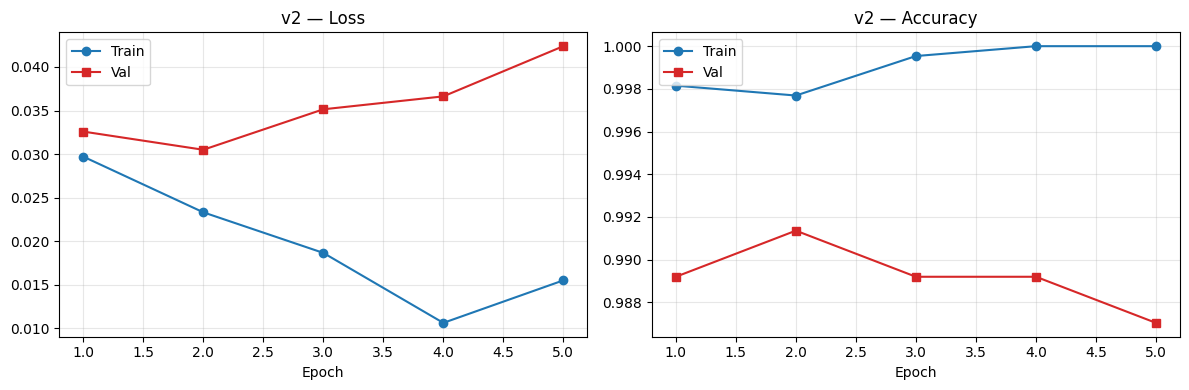

In [ ]:
# ============================================================
# ЯЧЕЙКА C. График обучения v2
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_x = np.arange(1, FINETUNE_EPOCHS_V2 + 1)

axes[0].plot(epochs_x, finetune_v2_history['train_loss'], 'o-', label='Train', color='#1f77b4')
axes[0].plot(epochs_x, finetune_v2_history['val_loss'],   's-', label='Val',   color='#d62728')
axes[0].set_title('v2 — Loss');     axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_x, finetune_v2_history['train_acc'], 'o-', label='Train', color='#1f77b4')
axes[1].plot(epochs_x, finetune_v2_history['val_acc'],   's-', label='Val',   color='#d62728')
axes[1].set_title('v2 — Accuracy'); axes[1].set_xlabel('Epoch')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('v2_training_curve.png', dpi=150)
plt.show()

# Оценка защищенной модели v1

ROBUST — ЧИСТЫЕ ДАННЫЕ (после дообучения)
Accuracy:  0.9914
Precision: 0.9901
Recall:    0.9919
F1-Score:  0.9910


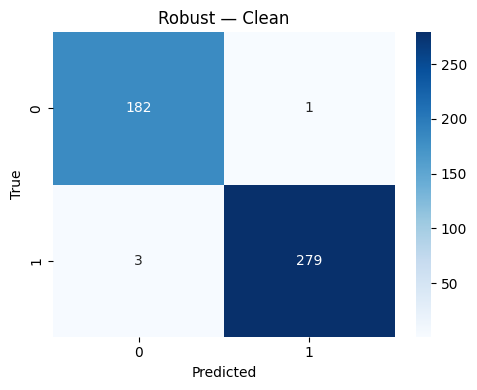


Robust — FGSM Accuracy: 0.9634


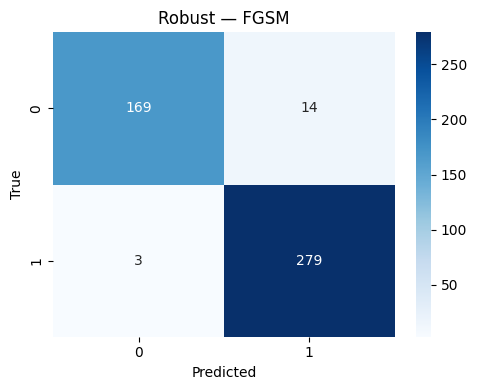

Robust — PGD Accuracy: 0.9161


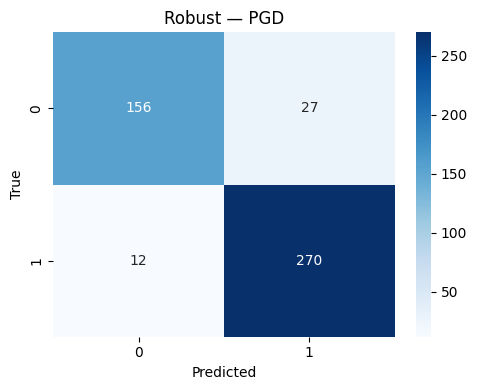

array([[156,  27],
       [ 12, 270]])

In [ ]:
clean_metrics = evaluate(robust_model, test_loader, criterion, device, return_predictions=True)

print("=" * 60)
print("ROBUST — ЧИСТЫЕ ДАННЫЕ (после дообучения)")
print("=" * 60)
print(f"Accuracy:  {clean_metrics['accuracy']:.4f}")
print(f"Precision: {clean_metrics['precision']:.4f}")
print(f"Recall:    {clean_metrics['recall']:.4f}")
print(f"F1-Score:  {clean_metrics['f1']:.4f}")
plot_confusion_matrix(clean_metrics['preds'], clean_metrics['labels'],
                      'Robust — Clean', class_names)

# FGSM
fgsm_robust = torchattacks.FGSM(robust_model, eps=8/255)
robust_fgsm = evaluate_under_attack(
    robust_model, fgsm_robust, test_loader, device, return_predictions=True)
robust_fgsm_acc = robust_fgsm['accuracy']
print(f"\nRobust — FGSM Accuracy: {robust_fgsm_acc:.4f}")
plot_confusion_matrix(robust_fgsm['preds'], robust_fgsm['labels'],
                      'Robust — FGSM', class_names)

# PGD
pgd_robust = torchattacks.PGD(robust_model, eps=8/255, alpha=2/255, steps=10)
robust_pgd = evaluate_under_attack(
    robust_model, pgd_robust, test_loader, device, return_predictions=True)
robust_pgd_acc = robust_pgd['accuracy']
print(f"Robust — PGD Accuracy: {robust_pgd_acc:.4f}")
plot_confusion_matrix(robust_pgd['preds'], robust_pgd['labels'],
                      'Robust — PGD', class_names)

In [ ]:
def evaluate_on_rotations(model, dataset, angles, device, batch_size=32):
    """Оценка accuracy на повёрнутых изображениях (без ресайза, только поворот)."""
    model.eval()
    base_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    base_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    results = {}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for angle in angles:
        correct = 0
        total = 0
        for images, labels in loader:
            # денормализуем -> поворот -> нормализуем
            images = images * base_std + base_mean
            images = torch.clamp(images, 0, 1)
            images = torch.stack([TF.rotate(img, angle) for img in images])
            images = (images - base_mean) / base_std
            images, labels = images.to(device), labels.to(device)
            with torch.no_grad():
                outputs = model(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
        results[angle] = correct / total
    return results


def evaluate_on_noise(model, dataset, stds, device, batch_size=32):
    """Шум добавляем в ненормализованном пространстве, как и при обучении."""
    model.eval()
    base_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    base_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    results = {}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for std in stds:
        correct = 0
        total = 0
        for images, labels in loader:
            images = images * base_std + base_mean
            images = torch.clamp(images + torch.randn_like(images) * std, 0, 1)
            images = (images - base_mean) / base_std
            images, labels = images.to(device), labels.to(device)
            with torch.no_grad():
                outputs = model(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
        results[std] = correct / total
    return results


angles = [-30, -15, 15, 30]
noise_stds = [0.05, 0.1, 0.15]

print("=" * 60)
print("УСТОЙЧИВОСТЬ К ПОВОРОТАМ")
print("=" * 60)
baseline_rot = evaluate_on_rotations(baseline_model, test_dataset, angles, device)
robust_rot = evaluate_on_rotations(robust_model, test_dataset, angles, device)
for a in angles:
    print(f"  angle={a:>3}°: baseline={baseline_rot[a]:.4f}, robust={robust_rot[a]:.4f}")

print("\n" + "=" * 60)
print("УСТОЙЧИВОСТЬ К ГАУССОВСКОМУ ШУМУ")
print("=" * 60)
baseline_noise = evaluate_on_noise(baseline_model, test_dataset, noise_stds, device)
robust_noise = evaluate_on_noise(robust_model, test_dataset, noise_stds, device)
for s in noise_stds:
    print(f"  std={s:.2f}: baseline={baseline_noise[s]:.4f}, robust={robust_noise[s]:.4f}")

УСТОЙЧИВОСТЬ К ПОВОРОТАМ
  angle=-30°: baseline=0.6688, robust=0.9570
  angle=-15°: baseline=0.8860, robust=0.9677
  angle= 15°: baseline=0.9548, robust=0.9699
  angle= 30°: baseline=0.7914, robust=0.9699

УСТОЙЧИВОСТЬ К ГАУССОВСКОМУ ШУМУ
  std=0.05: baseline=0.9505, robust=0.9892
  std=0.10: baseline=0.6452, robust=0.9742
  std=0.15: baseline=0.6065, robust=0.9570


In [ ]:
print("=" * 78)
print("СРАВНЕНИЕ УСТОЙЧИВОСТИ")
print("=" * 78)
header = f"{'Model':<12} {'Clean':<9} {'FGSM':<9} {'PGD':<9} {'Rot-30°':<9} {'Noise 0.1':<9}"
print(header)
print("-" * 78)
print(f"{'Baseline':<12} "
      f"{test_metrics_baseline['accuracy']:<9.4f} "
      f"{baseline_fgsm_acc:<9.4f} "
      f"{baseline_pgd_acc:<9.4f} "
      f"{baseline_rot[-30]:<9.4f} "
      f"{baseline_noise[0.1]:<9.4f}")
print(f"{'Robust':<12} "
      f"{clean_metrics['accuracy']:<9.4f} "
      f"{robust_fgsm_acc:<9.4f} "
      f"{robust_pgd_acc:<9.4f} "
      f"{robust_rot[15]:<9.4f} "
      f"{robust_noise[0.1]:<9.4f}")

СРАВНЕНИЕ УСТОЙЧИВОСТИ
Model        Clean     FGSM      PGD       Rot-30°   Noise 0.1
------------------------------------------------------------------------------
Baseline     0.9785    0.6065    0.2882    0.6688    0.6452   
Robust       0.9914    0.9634    0.9161    0.9699    0.9742   


V2 — ЧИСТЫЕ ДАННЫЕ
Accuracy:  0.9892
Precision: 0.9892
Recall:    0.9883
F1-Score:  0.9887
Loss:      0.0314


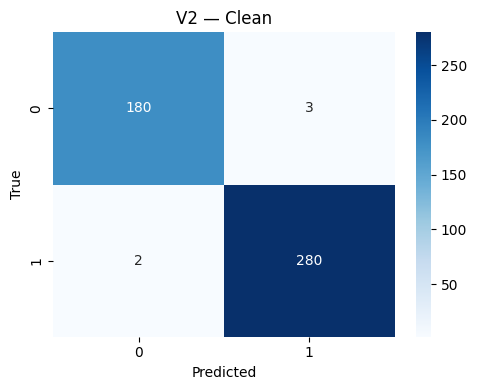


V2 — FGSM Accuracy: 0.9591


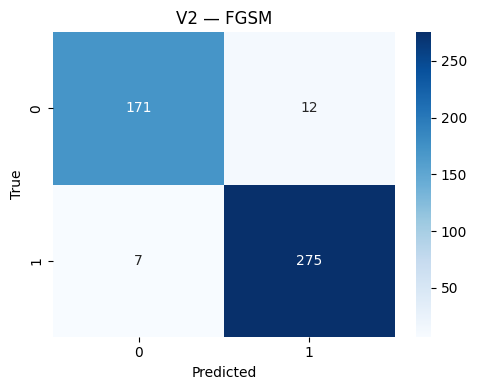

V2 — PGD Accuracy: 0.8903


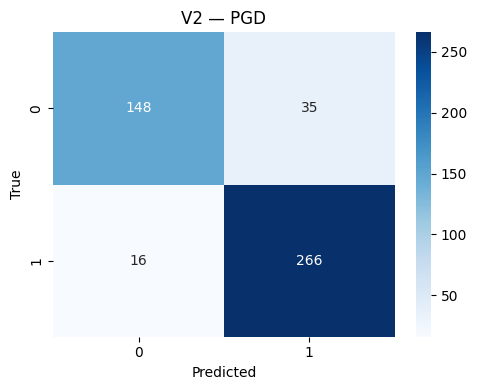

array([[148,  35],
       [ 16, 266]])

In [ ]:
# ============================================================
# ЯЧЕЙКА D. Оценка v2 на тестовой выборке (clean, FGSM, PGD)
# ============================================================
v2_clean_metrics = evaluate(
    robust_model_v2, test_loader, criterion, DEVICE, return_predictions=True)

print("=" * 60)
print("V2 — ЧИСТЫЕ ДАННЫЕ")
print("=" * 60)
print(f"Accuracy:  {v2_clean_metrics['accuracy']:.4f}")
print(f"Precision: {v2_clean_metrics['precision']:.4f}")
print(f"Recall:    {v2_clean_metrics['recall']:.4f}")
print(f"F1-Score:  {v2_clean_metrics['f1']:.4f}")
print(f"Loss:      {v2_clean_metrics['loss']:.4f}")

plot_confusion_matrix(v2_clean_metrics['preds'], v2_clean_metrics['labels'],
                      'V2 — Clean', class_names)

# FGSM
fgsm_v2 = torchattacks.FGSM(robust_model_v2, eps=8/255)
v2_fgsm = evaluate_under_attack(
    robust_model_v2, fgsm_v2, test_loader, DEVICE, return_predictions=True)
v2_fgsm_acc = v2_fgsm['accuracy']
print(f"\nV2 — FGSM Accuracy: {v2_fgsm_acc:.4f}")
plot_confusion_matrix(v2_fgsm['preds'], v2_fgsm['labels'],
                      'V2 — FGSM', class_names)

# PGD
pgd_v2 = torchattacks.PGD(robust_model_v2, eps=8/255, alpha=2/255, steps=10)
v2_pgd = evaluate_under_attack(
    robust_model_v2, pgd_v2, test_loader, DEVICE, return_predictions=True)
v2_pgd_acc = v2_pgd['accuracy']
print(f"V2 — PGD Accuracy: {v2_pgd_acc:.4f}")
plot_confusion_matrix(v2_pgd['preds'], v2_pgd['labels'],
                      'V2 — PGD', class_names)

In [ ]:
# ============================================================
# ЯЧЕЙКА E. Устойчивость v2 к поворотам и шуму (аналогично v1)
# ============================================================
angles = [-30, -15, 15, 30]
noise_stds = [0.05, 0.1, 0.15]

print("=" * 60)
print("V2 — УСТОЙЧИВОСТЬ К ПОВОРОТАМ")
print("=" * 60)
v2_rot = evaluate_on_rotations(robust_model_v2, test_dataset, angles, DEVICE)
for a in angles:
    print(f"  angle={a:>3}°: v1={robust_rot[a]:.4f}, v2={v2_rot[a]:.4f}")

print("\n" + "=" * 60)
print("V2 — УСТОЙЧИВОСТЬ К ГАУССОВСКОМУ ШУМУ")
print("=" * 60)
v2_noise = evaluate_on_noise(robust_model_v2, test_dataset, noise_stds, DEVICE)
for s in noise_stds:
    print(f"  std={s:.2f}: v1={robust_noise[s]:.4f}, v2={v2_noise[s]:.4f}")

V2 — УСТОЙЧИВОСТЬ К ПОВОРОТАМ
  angle=-30°: v1=0.9570, v2=0.9505
  angle=-15°: v1=0.9677, v2=0.9699
  angle= 15°: v1=0.9699, v2=0.9763
  angle= 30°: v1=0.9699, v2=0.9570

V2 — УСТОЙЧИВОСТЬ К ГАУССОВСКОМУ ШУМУ
  std=0.05: v1=0.9892, v2=0.9914
  std=0.10: v1=0.9742, v2=0.9892
  std=0.15: v1=0.9570, v2=0.9871


Считаем TTA для v1 (clean + rot + noise)...
Считаем TTA для v2 (clean + rot + noise)...

ИТОГОВОЕ СРАВНЕНИЕ: baseline / v1 / v2 / v2 + TTA
Model          Clean     FGSM      PGD       Rot-30°   Rot+15°   Noise0.1 
--------------------------------------------------------------------------------------------
Baseline       0.9785    0.6065    0.2882    0.6688    0.9548    0.6452   
v1 (robust)    0.9914    0.9634    0.9161    0.9570    0.9699    0.9742   
v2 (new)       0.9892    0.9591    0.8903    0.9505    0.9763    0.9892   
v1 + TTA       0.9849    —         —         0.9462    0.9720    0.9656   
v2 + TTA       0.9871    —         —         0.9570    0.9763    0.9828   


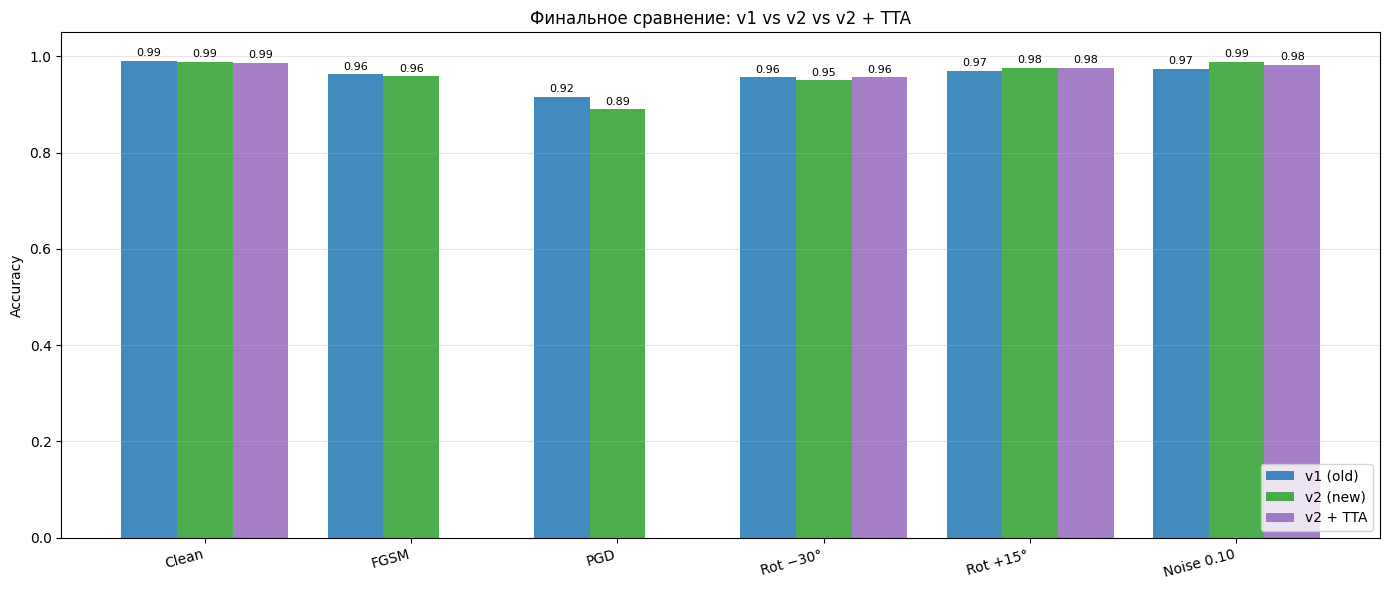

In [ ]:
# ============================================================
# ЯЧЕЙКА F. TTA-оценка и итоговое сравнение v1 / v2 / v2+TTA
# ============================================================

# ---- 1) TTA-оценка на clean ----
def eval_clean_tta(model, base_dataset, subset, device):
    correct, total = 0, 0
    for i in range(len(subset)):
        real_idx = subset.indices[i]
        img_path, label = base_dataset.samples[real_idx]
        img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        pred, _ = predict_pil_with_tta(model, img, device)
        total += 1
        correct += (pred == label)
    return correct / total


# ---- 2) TTA-оценка на поворотах ----
def eval_rot_tta(model, base_dataset, subset, device, angles):
    results = {}
    for angle in angles:
        correct, total = 0, 0
        for i in range(len(subset)):
            real_idx = subset.indices[i]
            img_path, label = base_dataset.samples[real_idx]
            img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            img = TF.rotate(img, angle)
            pred, _ = predict_pil_with_tta(model, img, device)
            total += 1
            correct += (pred == label)
        results[angle] = correct / total
    return results


# ---- 3) TTA-оценка на шуме ----
def eval_noise_tta(model, base_dataset, subset, device, noise_stds):
    results = {}
    for std in noise_stds:
        correct, total = 0, 0
        np.random.seed(42)
        for i in range(len(subset)):
            real_idx = subset.indices[i]
            img_path, label = base_dataset.samples[real_idx]
            img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            arr = np.array(img).astype(np.float32)
            arr = np.clip(arr + np.random.normal(0, std * 255, arr.shape), 0, 255).astype(np.uint8)
            img = Image.fromarray(arr)
            pred, _ = predict_pil_with_tta(model, img, device)
            total += 1
            correct += (pred == label)
        results[std] = correct / total
    return results


# ---- 4) Считаем TTA для v1 и v2 ----
print("Считаем TTA для v1 (clean + rot + noise)...")
v1_clean_tta = eval_clean_tta(robust_model, full_dataset, test_dataset, DEVICE)
v1_rot_tta   = eval_rot_tta(robust_model, full_dataset, test_dataset, DEVICE, angles)
v1_noise_tta = eval_noise_tta(robust_model, full_dataset, test_dataset, DEVICE, noise_stds)

print("Считаем TTA для v2 (clean + rot + noise)...")
v2_clean_tta = eval_clean_tta(robust_model_v2, full_dataset, test_dataset, DEVICE)
v2_rot_tta   = eval_rot_tta(robust_model_v2, full_dataset, test_dataset, DEVICE, angles)
v2_noise_tta = eval_noise_tta(robust_model_v2, full_dataset, test_dataset, DEVICE, noise_stds)


# ---- 5) Итоговая таблица ----
print("\n" + "=" * 92)
print("ИТОГОВОЕ СРАВНЕНИЕ: baseline / v1 / v2 / v2 + TTA")
print("=" * 92)
header = (f"{'Model':<14} {'Clean':<9} {'FGSM':<9} {'PGD':<9} "
          f"{'Rot-30°':<9} {'Rot+15°':<9} {'Noise0.1':<9}")
print(header)
print("-" * 92)

print(f"{'Baseline':<14} "
      f"{test_metrics_baseline['accuracy']:<9.4f} "
      f"{baseline_fgsm_acc:<9.4f} "
      f"{baseline_pgd_acc:<9.4f} "
      f"{baseline_rot[-30]:<9.4f} "
      f"{baseline_rot[15]:<9.4f} "
      f"{baseline_noise[0.1]:<9.4f}")

print(f"{'v1 (robust)':<14} "
      f"{clean_metrics['accuracy']:<9.4f} "
      f"{robust_fgsm_acc:<9.4f} "
      f"{robust_pgd_acc:<9.4f} "
      f"{robust_rot[-30]:<9.4f} "
      f"{robust_rot[15]:<9.4f} "
      f"{robust_noise[0.1]:<9.4f}")

print(f"{'v2 (new)':<14} "
      f"{v2_clean_metrics['accuracy']:<9.4f} "
      f"{v2_fgsm_acc:<9.4f} "
      f"{v2_pgd_acc:<9.4f} "
      f"{v2_rot[-30]:<9.4f} "
      f"{v2_rot[15]:<9.4f} "
      f"{v2_noise[0.1]:<9.4f}")

print(f"{'v1 + TTA':<14} "
      f"{v1_clean_tta:<9.4f} "
      f"{'—':<9} "
      f"{'—':<9} "
      f"{v1_rot_tta[-30]:<9.4f} "
      f"{v1_rot_tta[15]:<9.4f} "
      f"{v1_noise_tta[0.1]:<9.4f}")

print(f"{'v2 + TTA':<14} "
      f"{v2_clean_tta:<9.4f} "
      f"{'—':<9} "
      f"{'—':<9} "
      f"{v2_rot_tta[-30]:<9.4f} "
      f"{v2_rot_tta[15]:<9.4f} "
      f"{v2_noise_tta[0.1]:<9.4f}")


# ---- 6) График ----
scenarios_lbl = ['Clean', 'FGSM', 'PGD', 'Rot −30°', 'Rot +15°', 'Noise 0.10']
v1_vals  = [clean_metrics['accuracy'], robust_fgsm_acc, robust_pgd_acc,
            robust_rot[-30], robust_rot[15], robust_noise[0.1]]
v2_vals  = [v2_clean_metrics['accuracy'], v2_fgsm_acc, v2_pgd_acc,
            v2_rot[-30], v2_rot[15], v2_noise[0.1]]
v2t_vals = [v2_clean_tta, np.nan, np.nan,
            v2_rot_tta[-30], v2_rot_tta[15], v2_noise_tta[0.1]]

x = np.arange(len(scenarios_lbl))
w = 0.27

fig, ax = plt.subplots(figsize=(14, 6))
b1 = ax.bar(x - w, v1_vals,  w, label='v1 (old)',  color='#1f77b4', alpha=0.85)
b2 = ax.bar(x,     v2_vals,  w, label='v2 (new)',  color='#2ca02c', alpha=0.85)
b3 = ax.bar(x + w, v2t_vals, w, label='v2 + TTA',  color='#9467bd', alpha=0.85)

for bars in (b1, b2, b3):
    for rect in bars:
        h = rect.get_height()
        if not np.isnan(h):
            ax.text(rect.get_x() + rect.get_width() / 2, h + 0.005,
                    f"{h:.2f}", ha='center', va='bottom', fontsize=8)

ax.set_xticks(x); ax.set_xticklabels(scenarios_lbl, rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Accuracy')
ax.set_title('Финальное сравнение: v1 vs v2 vs v2 + TTA')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('final_v1_v2_comparison.png', dpi=150)
plt.show()

In [ ]:
# ============================================================
# ЯЧЕЙКА G. Дополнительные оценщики:
#   blur / elastic / contrast / all_combined / sparse_fgsm / JSMA
# ============================================================
_MEAN_T = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD_T  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def _denorm(images): return torch.clamp(images * _STD_T + _MEAN_T, 0, 1)
def _norm(images):   return (images - _MEAN_T) / _STD_T


def evaluate_on_blur(model, dataset, sigmas, device, batch_size=32):
    model.eval()
    results = {}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for sigma in sigmas:
        blur = transforms.GaussianBlur(kernel_size=5, sigma=(sigma, sigma))
        correct, total = 0, 0
        for images, labels in loader:
            x = blur(_denorm(images))
            x = _norm(x).to(device); labels = labels.to(device)
            with torch.no_grad():
                preds = model(x).argmax(1)
            correct += preds.eq(labels).sum().item(); total += labels.size(0)
        results[sigma] = correct / total
    return results


def evaluate_on_elastic(model, dataset, alphas, device, batch_size=32):
    model.eval()
    results = {}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for alpha in alphas:
        elastic = transforms.ElasticTransform(alpha=alpha, sigma=5.0)
        correct, total = 0, 0
        for images, labels in loader:
            x = elastic(_denorm(images))
            x = _norm(x).to(device); labels = labels.to(device)
            with torch.no_grad():
                preds = model(x).argmax(1)
            correct += preds.eq(labels).sum().item(); total += labels.size(0)
        results[alpha] = correct / total
    return results


def evaluate_on_contrast(model, dataset, factors, device, batch_size=32):
    model.eval()
    results = {}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for factor in factors:
        jitter = transforms.ColorJitter(contrast=(factor, factor))
        correct, total = 0, 0
        for images, labels in loader:
            x = jitter(_denorm(images))
            x = _norm(x).to(device); labels = labels.to(device)
            with torch.no_grad():
                preds = model(x).argmax(1)
            correct += preds.eq(labels).sum().item(); total += labels.size(0)
        results[factor] = correct / total
    return results


def evaluate_on_all_combined(model, dataset, device, batch_size=32,
                             rotate_angle=15, noise_std=0.10,
                             blur_sigma=1.0, contrast_factor=1.5,
                             elastic_alpha=50.0):
    """Все искажения сразу: elastic → contrast → rotate → noise → blur."""
    model.eval()
    correct, total = 0, 0
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    elastic = transforms.ElasticTransform(alpha=elastic_alpha, sigma=5.0)
    jitter  = transforms.ColorJitter(contrast=(contrast_factor, contrast_factor))
    blur    = transforms.GaussianBlur(kernel_size=5, sigma=(blur_sigma, blur_sigma))

    for images, labels in loader:
        x = _denorm(images)
        x = elastic(x); x = jitter(x)
        x = torch.stack([TF.rotate(img, rotate_angle) for img in x])
        x = torch.clamp(x + torch.randn_like(x) * noise_std, 0, 1)
        x = blur(x)
        x = _norm(x).to(device); labels = labels.to(device)
        with torch.no_grad():
            preds = model(x).argmax(1)
        correct += preds.eq(labels).sum().item(); total += labels.size(0)
    return correct / total


def evaluate_sparse_fgsm(model, loader, device, k=200, eps=8/255):
    model.eval()
    correct, total = 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        adv = sparse_fgsm_attack(model, images, labels, k=k, eps=eps)
        with torch.no_grad():
            preds = model(adv).argmax(1)
        correct += preds.eq(labels).sum().item(); total += labels.size(0)
    return correct / total


# ---------- JSMA (пер-изображение, поэтому на сэмпле) ----------
def jsma_attack(model, image_tensor, target_label, theta=0.1, top_k=50, max_iter=30):
    x_adv = image_tensor.clone().detach().to(DEVICE)
    min_val, max_val = -2.2, 2.7
    for _ in range(max_iter):
        x_adv.requires_grad = True
        logits = model(x_adv)
        if torch.argmax(logits) == target_label:
            break
        target_logit = logits[0, target_label]
        other_logit  = logits[0, 1 - target_label]
        model.zero_grad()
        grad_t = torch.autograd.grad(target_logit, x_adv, retain_graph=True)[0]
        grad_o = torch.autograd.grad(other_logit,  x_adv, retain_graph=True)[0]
        saliency = torch.where((grad_t > 0) & (grad_o < 0),
                               grad_t * torch.abs(grad_o),
                               torch.zeros_like(grad_t))
        flat = saliency.view(-1)
        topk = torch.topk(flat, k=top_k).indices
        pert = torch.zeros_like(flat); pert[topk] = theta
        pert = pert.view(1, 3, 224, 224)
        x_adv = torch.clamp(x_adv.detach() + pert, min_val, max_val)
    return x_adv.detach()


def evaluate_jsma_sample(model, base_dataset, subset, device,
                          n_samples=100, theta=0.15, top_k=100, max_iter=25, seed=42):
    """
    JSMA-оценка на случайном сэмпле из clean-correct примеров.
    Возвращает {'accuracy_after', 'flip_rate', 'changed_percent', 'n_processed'}.
    accuracy_after = доля примеров, оставшихся правильно классифицированными после атаки.
    """
    model.eval()
    random.seed(seed)
    indices = list(range(len(subset)))
    random.shuffle(indices)

    correct_after, n_processed, changes = 0, 0, []

    for i in indices:
        if n_processed >= n_samples:
            break
        real_idx = subset.indices[i]
        img_path, true_label = base_dataset.samples[real_idx]
        img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        x_norm = baseline_transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            clean_pred = model(x_norm).argmax(1).item()
        if clean_pred != true_label:
            continue

        x_adv = jsma_attack(model, x_norm, 1 - true_label,
                            theta=theta, top_k=top_k, max_iter=max_iter)
        with torch.no_grad():
            adv_pred = model(x_adv).argmax(1).item()

        correct_after += int(adv_pred == true_label)
        diff = (x_adv - x_norm).abs().sum(dim=1)
        changes.append((diff > 0).float().mean().item() * 100)
        n_processed += 1

    if n_processed == 0:
        return {'accuracy_after': float('nan'), 'flip_rate': float('nan'),
                'changed_percent': float('nan'), 'n_processed': 0}

    return {
        'accuracy_after': correct_after / n_processed,
        'flip_rate':       1 - correct_after / n_processed,
        'changed_percent': float(np.mean(changes)),
        'n_processed':     n_processed,
    }


print("Дополнительные оценщики готовы")

Дополнительные оценщики готовы


In [ ]:
# ============================================================
# ЯЧЕЙКА H. Универсальная функция — все атаки + все искажения
# ============================================================
def comprehensive_evaluate(model, model_name, device,
                            run_jsma=True, jsma_n=100):
    print(f"\n{'=' * 66}\n{model_name}\n{'=' * 66}")
    results = {}

    # ---------- 1) Adversarial ----------
    results['Clean']  = evaluate(model, test_loader, criterion, device)['accuracy']
    print(f"  {'Clean':<12} {results['Clean']:.4f}")

    fgsm = torchattacks.FGSM(model, eps=8/255)
    results['FGSM'] = evaluate_under_attack(model, fgsm, test_loader, device)['accuracy']
    print(f"  {'FGSM':<12} {results['FGSM']:.4f}")

    pgd = torchattacks.PGD(model, eps=8/255, alpha=2/255, steps=10)
    results['PGD'] = evaluate_under_attack(model, pgd, test_loader, device)['accuracy']
    print(f"  {'PGD':<12} {results['PGD']:.4f}")

    results['Sparse'] = evaluate_sparse_fgsm(model, test_loader, device)
    print(f"  {'Sparse':<12} {results['Sparse']:.4f}")

    # ---------- 2) Natural distortions ----------
    results['Rot-30']    = evaluate_on_rotations(model, test_dataset, [-30],  device)[-30]
    results['Rot+30']    = evaluate_on_rotations(model, test_dataset, [ 30],  device)[ 30]
    results['Noise0.10'] = evaluate_on_noise(model,     test_dataset, [0.10], device)[0.10]
    results['Noise0.15'] = evaluate_on_noise(model,     test_dataset, [0.15], device)[0.15]
    results['Blur']      = evaluate_on_blur(model,      test_dataset, [1.0],  device)[1.0]
    results['Elastic']   = evaluate_on_elastic(model,   test_dataset, [50.0], device)[50.0]
    results['Contrast']  = evaluate_on_contrast(model,  test_dataset, [1.5],  device)[1.5]
    results['All']       = evaluate_on_all_combined(model, test_dataset, device)

    for k in ['Rot-30', 'Rot+30', 'Noise0.10', 'Noise0.15',
              'Blur', 'Elastic', 'Contrast', 'All']:
        print(f"  {k:<12} {results[k]:.4f}")

    # ---------- 3) JSMA ----------
    if run_jsma:
        jsma = evaluate_jsma_sample(model, full_dataset, test_dataset,
                                     device, n_samples=jsma_n)
        results['JSMA'] = jsma['accuracy_after']
        print(f"  {'JSMA':<12} {jsma['accuracy_after']:.4f}  "
              f"(flip={jsma['flip_rate']*100:.1f}%, "
              f"изменено пикселей: {jsma['changed_percent']:.2f}%, "
              f"n={jsma['n_processed']})")

    return results


# ---------- Запуск на трёх моделях ----------
print("\n" + "#" * 66)
print("#  ПОЛНОЕ ТЕСТИРОВАНИЕ ВСЕХ МОДЕЛЕЙ")
print("#  Может занять 5–10 минут (JSMA — самая медленная)")
print("#" * 66)

results_baseline = comprehensive_evaluate(baseline_model,    "BASELINE",   DEVICE, jsma_n=100)
results_v1       = comprehensive_evaluate(robust_model,      "V1 (robust)", DEVICE, jsma_n=100)
results_v2       = comprehensive_evaluate(robust_model_v2,   "V2 (new)",    DEVICE, jsma_n=100)


##################################################################
#  ПОЛНОЕ ТЕСТИРОВАНИЕ ВСЕХ МОДЕЛЕЙ
#  Может занять 5–10 минут (JSMA — самая медленная)
##################################################################

BASELINE
  Clean        0.9785
  FGSM         0.6065
  PGD          0.2882
  Sparse       0.9785
  Rot-30       0.6688
  Rot+30       0.7914
  Noise0.10    0.6559
  Noise0.15    0.6065
  Blur         0.9269
  Elastic      0.9505
  Contrast     0.9656
  All          0.8495
  JSMA         0.0900  (flip=91.0%, изменено пикселей: 1.20%, n=100)

V1 (robust)
  Clean        0.9914
  FGSM         0.9634
  PGD          0.9161
  Sparse       0.9871
  Rot-30       0.9570
  Rot+30       0.9699
  Noise0.10    0.9763
  Noise0.15    0.9699
  Blur         0.9849
  Elastic      0.9785
  Contrast     0.9806
  All          0.9570
  JSMA         0.6900  (flip=31.0%, изменено пикселей: 0.72%, n=100)

V2 (new)
  Clean        0.9892
  FGSM         0.9591
  PGD          0.8903
  Sparse    


ПОЛНОЕ СРАВНЕНИЕ: Baseline vs V1 vs V2 (все сценарии)
Metric       Baseline    V1          V2          Δ(V2−V1)     Δ(V2−BL)    
------------------------------------------------------------------------------
Clean        0.9785      0.9914      0.9892      -0.0022     +0.0108     
FGSM         0.6065      0.9634      0.9591      -0.0043     +0.3527     
PGD          0.2882      0.9161      0.8903      -0.0258     +0.6022     
Sparse       0.9785      0.9871      0.9892      +0.0022      +0.0108     
Rot-30       0.6688      0.9570      0.9505      -0.0065     +0.2817     
Rot+30       0.7914      0.9699      0.9570      -0.0129     +0.1656     
Noise0.10    0.6559      0.9763      0.9892      +0.0129      +0.3333     
Noise0.15    0.6065      0.9699      0.9892      +0.0194      +0.3828     
Blur         0.9269      0.9849      0.9849      +0.0000      +0.0581     
Elastic      0.9505      0.9785      0.9828      +0.0043      +0.0323     
Contrast     0.9656      0.9806      0.9871   

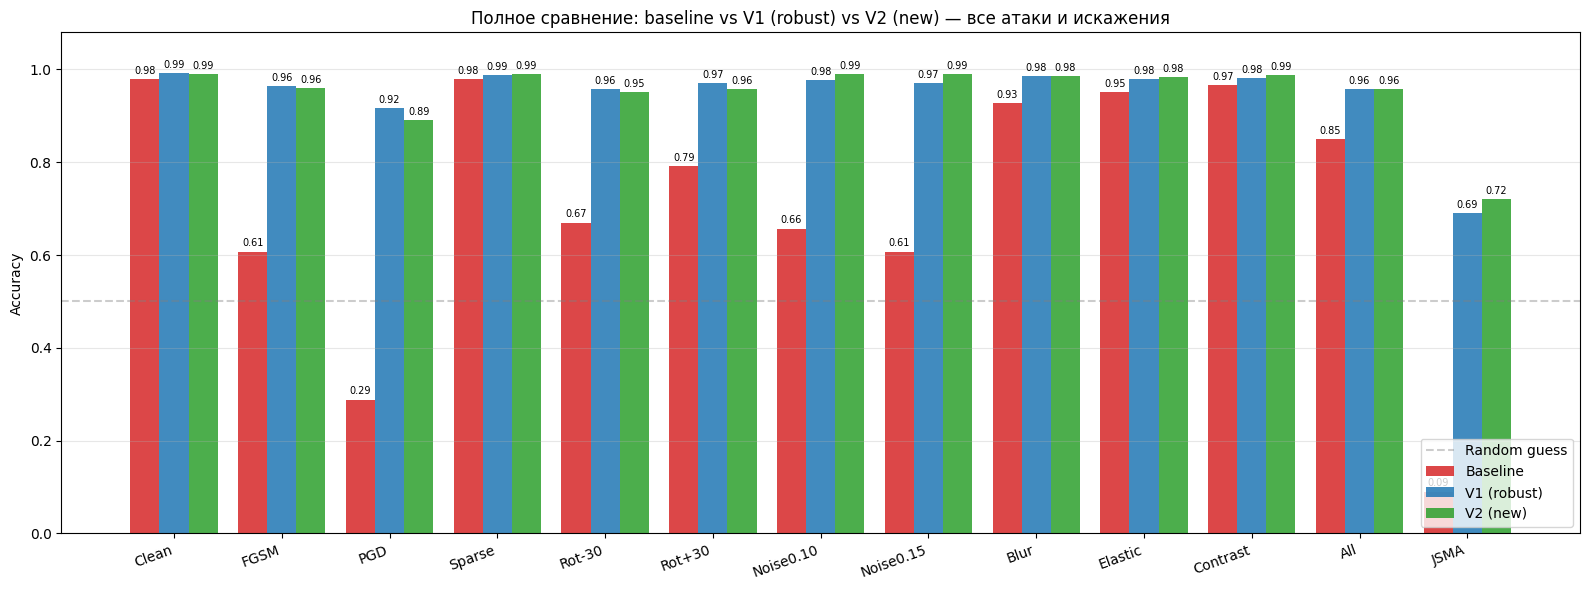

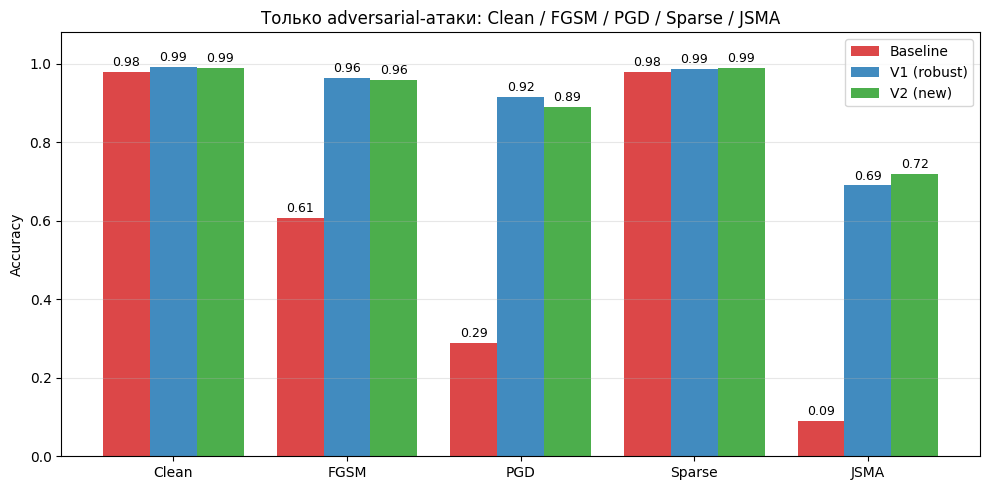

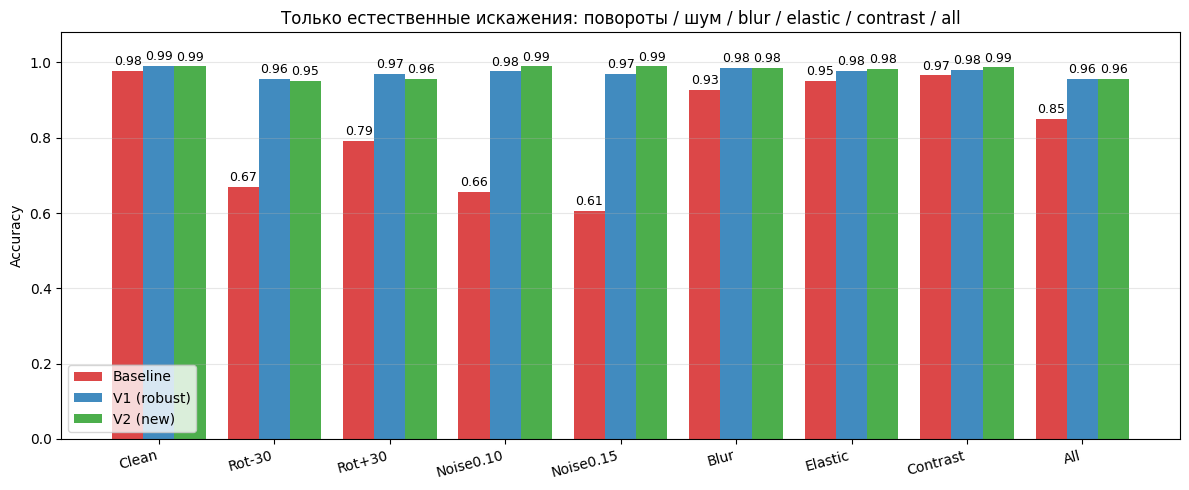

In [ ]:
# ============================================================
# ЯЧЕЙКА I. Сводная таблица + визуальное сравнение
# ============================================================
all_metrics = ['Clean', 'FGSM', 'PGD', 'Sparse',
               'Rot-30', 'Rot+30', 'Noise0.10', 'Noise0.15',
               'Blur', 'Elastic', 'Contrast', 'All', 'JSMA']
all_metrics = [m for m in all_metrics if m in results_baseline]

# ---------- 1) Таблица ----------
print("\n" + "=" * 78)
print("ПОЛНОЕ СРАВНЕНИЕ: Baseline vs V1 vs V2 (все сценарии)")
print("=" * 78)
print(f"{'Metric':<12} {'Baseline':<11} {'V1':<11} {'V2':<11} "
      f"{'Δ(V2−V1)':<12} {'Δ(V2−BL)':<12}")
print("-" * 78)

for m in all_metrics:
    b  = results_baseline.get(m, float('nan'))
    v1 = results_v1.get(m, float('nan'))
    v2 = results_v2.get(m, float('nan'))
    d_v1 = v2 - v1
    d_bl = v2 - b
    s1 = "+" if d_v1 >= 0 else ""
    s2 = "+" if d_bl >= 0 else ""
    print(f"{m:<12} {b:<11.4f} {v1:<11.4f} {v2:<11.4f} "
          f"{s1}{d_v1:<11.4f} {s2}{d_bl:<11.4f}")


# ---------- 2) Сгруппированный график ----------
x = np.arange(len(all_metrics))
w = 0.27

b_vals  = [results_baseline.get(m, 0) for m in all_metrics]
v1_vals = [results_v1.get(m, 0)       for m in all_metrics]
v2_vals = [results_v2.get(m, 0)       for m in all_metrics]

fig, ax = plt.subplots(figsize=(16, 6))
bars_b  = ax.bar(x - w, b_vals,  w, label='Baseline',   color='#d62728', alpha=0.85)
bars_1  = ax.bar(x,     v1_vals, w, label='V1 (robust)', color='#1f77b4', alpha=0.85)
bars_2  = ax.bar(x + w, v2_vals, w, label='V2 (new)',    color='#2ca02c', alpha=0.85)

for bars in (bars_b, bars_1, bars_2):
    for rect in bars:
        h = rect.get_height()
        if not np.isnan(h):
            ax.text(rect.get_x() + rect.get_width() / 2, h + 0.008,
                    f"{h:.2f}", ha='center', va='bottom', fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(all_metrics, rotation=20, ha='right')
ax.set_ylim(0, 1.08)
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.4, label='Random guess')
ax.set_ylabel('Accuracy')
ax.set_title('Полное сравнение: baseline vs V1 (robust) vs V2 (new) — все атаки и искажения')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('comprehensive_comparison.png', dpi=150)
plt.show()


# ---------- 3) Отдельный график для adversarial (без искажений) ----------
adv_metrics = [m for m in ['Clean', 'FGSM', 'PGD', 'Sparse', 'JSMA']
               if m in results_baseline]

fig, ax = plt.subplots(figsize=(10, 5))
x2 = np.arange(len(adv_metrics))
b2  = [results_baseline.get(m, 0) for m in adv_metrics]
v12 = [results_v1.get(m, 0)       for m in adv_metrics]
v22 = [results_v2.get(m, 0)       for m in adv_metrics]

ax.bar(x2 - w, b2,  w, label='Baseline',    color='#d62728', alpha=0.85)
ax.bar(x2,     v12, w, label='V1 (robust)', color='#1f77b4', alpha=0.85)
ax.bar(x2 + w, v22, w, label='V2 (new)',    color='#2ca02c', alpha=0.85)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f', fontsize=9, padding=2)

ax.set_xticks(x2); ax.set_xticklabels(adv_metrics)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Accuracy')
ax.set_title('Только adversarial-атаки: Clean / FGSM / PGD / Sparse / JSMA')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('adversarial_comparison.png', dpi=150)
plt.show()


# ---------- 4) Отдельный график для искажений ----------
nat_metrics = [m for m in ['Clean', 'Rot-30', 'Rot+30', 'Noise0.10',
                           'Noise0.15', 'Blur', 'Elastic', 'Contrast', 'All']
               if m in results_baseline]

fig, ax = plt.subplots(figsize=(12, 5))
x3 = np.arange(len(nat_metrics))
b3  = [results_baseline.get(m, 0) for m in nat_metrics]
v13 = [results_v1.get(m, 0)       for m in nat_metrics]
v23 = [results_v2.get(m, 0)       for m in nat_metrics]

ax.bar(x3 - w, b3,  w, label='Baseline',    color='#d62728', alpha=0.85)
ax.bar(x3,     v13, w, label='V1 (robust)', color='#1f77b4', alpha=0.85)
ax.bar(x3 + w, v23, w, label='V2 (new)',    color='#2ca02c', alpha=0.85)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f', fontsize=9, padding=2)

ax.set_xticks(x3); ax.set_xticklabels(nat_metrics, rotation=15, ha='right')
ax.set_ylim(0, 1.08)
ax.set_ylabel('Accuracy')
ax.set_title('Только естественные искажения: повороты / шум / blur / elastic / contrast / all')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('natural_distortions_comparison.png', dpi=150)
plt.show()